# 01 · Análisis exploratorio de datos (EDA)

**Proyecto:** Predicción de riesgo de burnout organizacional · **Autor:** Oscar Paúl Naranjo Castro
**Maestría en Inteligencia Artificial, UEES** · Todas las rutas son relativas a la raíz del repositorio.

Objetivo: entender la estructura, calidad y patrones del dataset *Are Your Employees Burning Out?* antes de modelar, y justificar cada decisión de preprocesamiento.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Carga y estructura

In [2]:
from src.data_processing import load_raw_data
raw = load_raw_data()
print(raw.shape)
raw.head()

14:04:56 | INFO | src.data_processing | Datos cargados: 22750 filas, 9 columnas


(22750, 9)


,Employee ID,Date of Joining,Gender,Company Type,WFH Setup Available,Designation,Resource Allocation,Mental Fatigue Score,Burn Rate
0,fffe32003000360033003200,2008-09-30,Female,Service,No,2.0,3.0,3.8,0.16
1,fffe3700360033003500,2008-11-30,Male,Service,Yes,1.0,2.0,5.0,0.36
2,fffe31003300320037003900,2008-03-10,Female,Product,Yes,2.0,NaN,5.8,0.49
3,fffe32003400380032003900,2008-11-03,Male,Service,Yes,1.0,1.0,2.6,0.20
4,fffe31003900340031003600,2008-07-24,Female,Service,No,3.0,7.0,6.9,0.52


In [3]:
raw.dtypes.to_frame('tipo').assign(unicos=raw.nunique())

,tipo,unicos
Employee ID,str,22750
Date of Joining,str,366
Gender,str,2
Company Type,str,2
WFH Setup Available,str,2
Designation,float64,6
Resource Allocation,float64,10
Mental Fatigue Score,float64,101
Burn Rate,float64,101


In [4]:
raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee ID,22750,22750,fffe32003000360033003200,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Joining,22750,366,2008-01-06,86,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,22750,2,Female,11908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Company Type,22750,2,Service,14833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WFH Setup Available,22750,2,Yes,12290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Designation,22750.0,NaN,NaN,NaN,2.178725,1.135145,0.0,1.0,2.0,3.0,5.0
Resource Allocation,21369.0,NaN,NaN,NaN,4.481398,2.047211,1.0,3.0,4.0,6.0,10.0
Mental Fatigue Score,20633.0,NaN,NaN,NaN,5.728188,1.920839,0.0,4.6,5.9,7.1,10.0
Burn Rate,21626.0,NaN,NaN,NaN,0.452005,0.198226,0.0,0.31,0.45,0.59,1.0


## 2. Calidad de datos: valores faltantes

In [5]:
falt = raw.isna().agg(['sum', 'mean']).T.rename(columns={'sum': 'faltantes', 'mean': 'proporcion'})
falt[falt.faltantes > 0].round(4)

,faltantes,proporcion
Resource Allocation,1381.0,0.0607
Mental Fatigue Score,2117.0,0.0931
Burn Rate,1124.0,0.0494


In [6]:
# ¿Los faltantes se asocian con el nivel de burnout? (prueba de aleatoriedad)
for c in ['Mental Fatigue Score', 'Resource Allocation']:
    m = raw[c].isna()
    print(f"{c}: Burn Rate medio con faltante {raw.loc[m, 'Burn Rate'].mean():.3f} vs observado {raw.loc[~m, 'Burn Rate'].mean():.3f}")
print('Ambas variables faltantes a la vez:', (raw['Mental Fatigue Score'].isna() & raw['Resource Allocation'].isna()).sum())

Mental Fatigue Score: Burn Rate medio con faltante 0.452 vs observado 0.452
Resource Allocation: Burn Rate medio con faltante 0.449 vs observado 0.452
Ambas variables faltantes a la vez: 202


**Lectura.** Faltan el 9.3 % de *Mental Fatigue Score*, el 6.1 % de *Resource Allocation* y el 4.9 % del objetivo.
El Burn Rate medio es prácticamente igual con y sin dato, lo que es consistente con faltantes al azar (MCAR): imputar
por mediana no introduce un sesgo sistemático evidente, aunque sí pierde información individual. Las filas sin objetivo
se eliminan (imputarlas fabricaría etiquetas).

## 3. Variable objetivo: Burn Rate

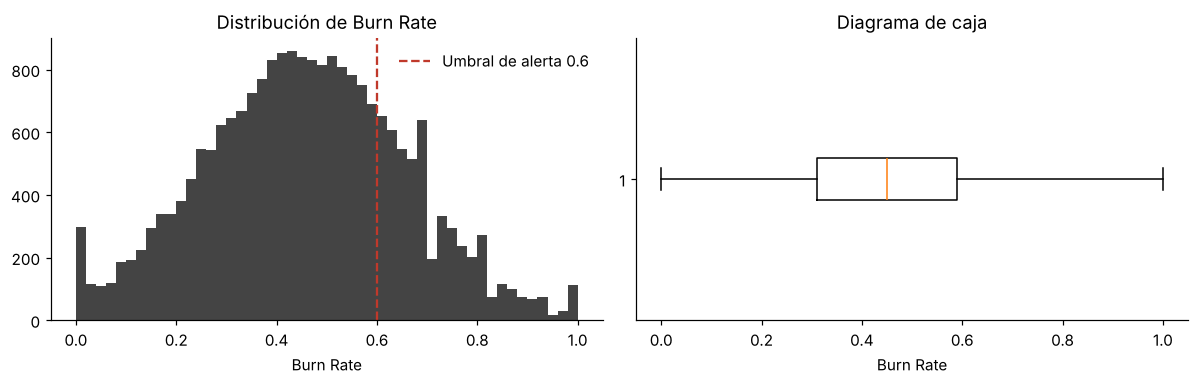

Media 0.452 | mediana 0.450 | asimetría 0.046 | riesgo alto (>=0.6) 23.8%


In [7]:
y = raw['Burn Rate'].dropna()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=50, color='#444'); ax[0].axvline(0.6, color='#c0392b', ls='--', label='Umbral de alerta 0.6')
ax[0].set_title('Distribución de Burn Rate'); ax[0].set_xlabel('Burn Rate'); ax[0].legend(frameon=False)
ax[1].boxplot(y, vert=False); ax[1].set_title('Diagrama de caja'); ax[1].set_xlabel('Burn Rate')
plt.tight_layout(); plt.savefig(FIG / 'eda_target.png', dpi=150); plt.show()
print(f"Media {y.mean():.3f} | mediana {y.median():.3f} | asimetría {y.skew():.3f} | riesgo alto (>=0.6) {(y>=0.6).mean():.1%}")

**Lectura.** La distribución es casi simétrica (asimetría ≈ 0.05) y centrada en 0.45. El 22.7 % de los registros
supera el umbral de 0.6: el problema de alerta tiene un desbalance moderado, por lo que se reportan sensibilidad y
precisión además de exactitud.

## 4. Variables numéricas

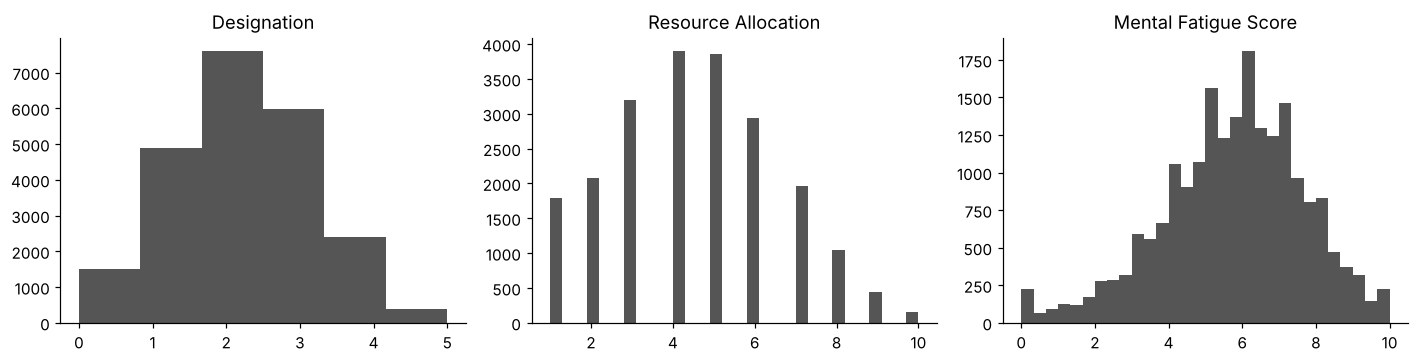

In [8]:
num = ['Designation', 'Resource Allocation', 'Mental Fatigue Score']
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, c in zip(ax, num):
    a.hist(raw[c].dropna(), bins=30 if c != 'Designation' else 6, color='#555'); a.set_title(c)
plt.tight_layout(); plt.savefig(FIG / 'eda_numeric_hist.png', dpi=150); plt.show()

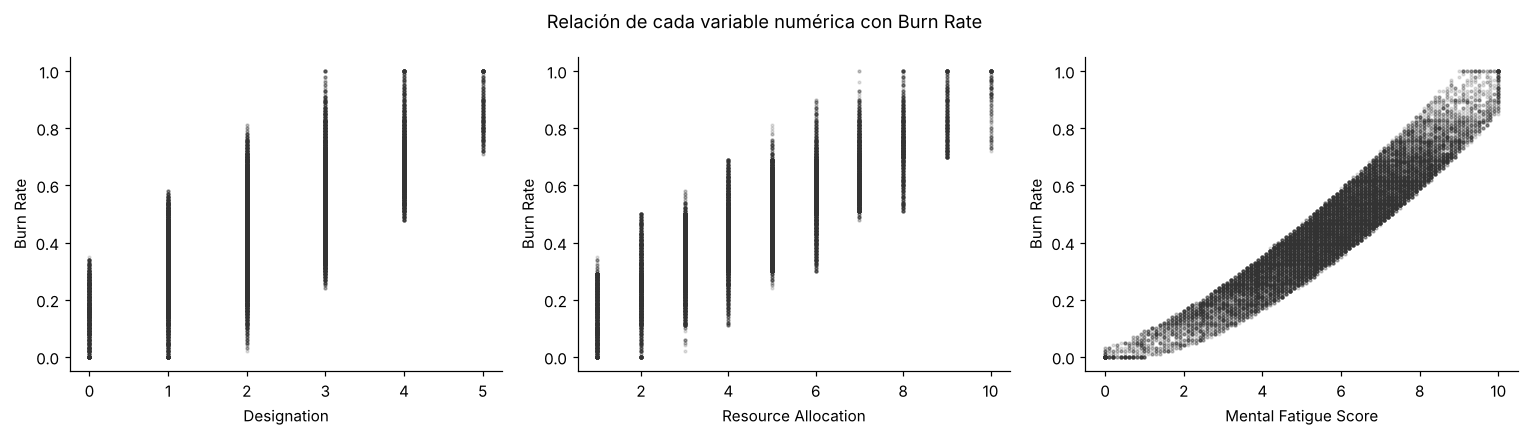

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, num):
    a.scatter(raw[c], raw['Burn Rate'], s=3, alpha=.15, color='#333')
    a.set_xlabel(c); a.set_ylabel('Burn Rate')
plt.suptitle('Relación de cada variable numérica con Burn Rate')
plt.tight_layout(); plt.savefig(FIG / 'eda_scatter.png', dpi=150); plt.show()

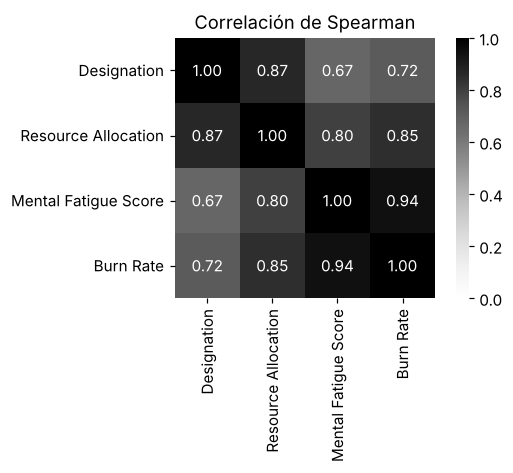

In [10]:
corr = raw[num + ['Burn Rate']].corr(method='spearman')
plt.figure(figsize=(5.5, 4.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Greys', vmin=0, vmax=1, square=True)
plt.title('Correlación de Spearman'); plt.tight_layout(); plt.savefig(FIG / 'eda_correlation.png', dpi=150); plt.show()

**Lectura.** *Mental Fatigue Score* tiene una relación casi lineal con el objetivo (ρ = 0.94), seguida de
*Resource Allocation* (0.85) y *Designation* (0.72). Las tres variables están muy correlacionadas entre sí
(Designation y Resource Allocation, ρ = 0.87): existe **multicolinealidad**, lo que favorece modelos de árboles
o regularizados y obliga a interpretar la importancia de variables con cuidado.

## 5. Variables categóricas

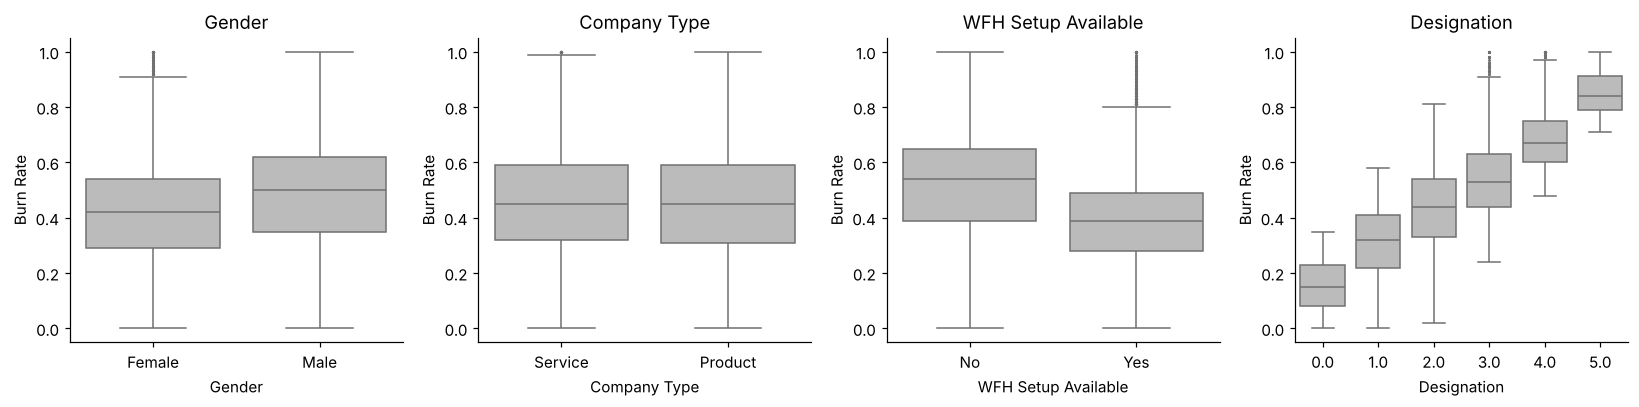

In [11]:
cats = ['Gender', 'Company Type', 'WFH Setup Available', 'Designation']
fig, ax = plt.subplots(1, 4, figsize=(15, 3.8))
for a, c in zip(ax, cats):
    sns.boxplot(data=raw, x=c, y='Burn Rate', ax=a, color='#bbb', fliersize=1)
    a.set_title(c)
plt.tight_layout(); plt.savefig(FIG / 'eda_categorical.png', dpi=150); plt.show()

In [12]:
tab = []
for c in cats:
    g = raw.dropna(subset=['Burn Rate']).groupby(c)['Burn Rate']
    tab.append(pd.DataFrame({'variable': c, 'n': g.size(), 'media': g.mean(), 'pct_riesgo_alto': g.apply(lambda s: (s >= .6).mean())}))
pd.concat(tab).round(3)

,variable,n,media,pct_riesgo_alto
Female,Gender,11349,0.423,0.183
Male,Gender,10277,0.484,0.299
Product,Company Type,7502,0.451,0.234
Service,Company Type,14124,0.453,0.241
No,WFH Setup Available,9941,0.518,0.359
Yes,WFH Setup Available,11685,0.396,0.136
0.0,Designation,1439,0.151,0.000
1.0,Designation,4632,0.308,0.000
2.0,Designation,7206,0.435,0.151
3.0,Designation,5698,0.545,0.338


**Lectura.**
* *Company Type* no separa el riesgo (0.451 vs 0.453).
* Sin teletrabajo el Burn Rate medio es mayor (0.518 vs 0.396), pero quienes no tienen teletrabajo también tienen
  más carga y fatiga: buena parte de esa diferencia está **confundida** con las variables numéricas.
* Los hombres muestran mayor Burn Rate medio (0.484 vs 0.423). La diferencia se acompaña de mayor carga y mayor
  proporción en niveles jerárquicos altos, lo cual es relevante para la auditoría de equidad.
* El riesgo crece de forma monótona con *Designation*; los niveles 0 y 1 no tienen ningún caso ≥ 0.6.

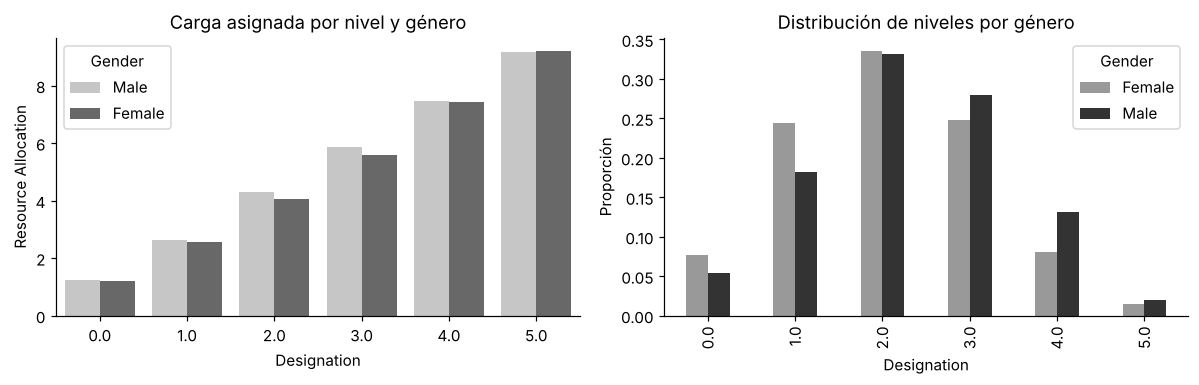

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.barplot(data=raw, x='Designation', y='Resource Allocation', hue='Gender', ax=ax[0], palette='Greys', errorbar=None)
ax[0].set_title('Carga asignada por nivel y género')
pd.crosstab(raw.Gender, raw.Designation, normalize='index').T.plot(kind='bar', ax=ax[1], color=['#999', '#333'])
ax[1].set_title('Distribución de niveles por género'); ax[1].set_ylabel('Proporción')
plt.tight_layout(); plt.savefig(FIG / 'eda_gender_context.png', dpi=150); plt.show()

## 6. Valores atípicos y variables descartadas

In [14]:
for c in ['Resource Allocation', 'Mental Fatigue Score', 'Burn Rate']:
    q1, q3 = raw[c].quantile([.25, .75]); i = q3 - q1
    print(f"{c}: {((raw[c] < q1 - 1.5*i) | (raw[c] > q3 + 1.5*i)).sum()} atípicos por IQR")
fechas = pd.to_datetime(raw['Date of Joining'])
antig = (fechas.max() - fechas).dt.days
print('Rango de fechas de ingreso:', fechas.min().date(), 'a', fechas.max().date())
print('Correlación antigüedad-Burn Rate:', round(antig.corr(raw['Burn Rate']), 4))

Resource Allocation: 0 atípicos por IQR
Mental Fatigue Score: 347 atípicos por IQR
Burn Rate: 0 atípicos por IQR
Rango de fechas de ingreso: 2008-01-01 a 2008-12-31
Correlación antigüedad-Burn Rate: 0.0014


**Lectura.** Los 347 atípicos de fatiga son valores bajos plausibles dentro de la escala 0 a 10; no se eliminan.
*Date of Joining* cubre solo el año 2008 y su correlación con el objetivo es nula (0.001), por lo que se descarta
junto con *Employee ID* (identificador sin valor predictivo).

## 7. Conclusiones del EDA
1. Problema de **regresión** con objetivo continuo y casi simétrico; se añade una lectura binaria (umbral 0.6) para la alerta.
2. La fatiga mental domina la señal: cualquier modelo debe superar a un **baseline de una sola variable**.
3. Faltantes compatibles con MCAR: imputación por mediana dentro del pipeline más **indicador de faltante**.
4. Multicolinealidad fuerte: se prefieren árboles con regularización (XGBoost) y explicaciones SHAP.
5. El dataset no tiene área ni departamento; los análisis organizacionales usan nivel, tipo de empresa y teletrabajo.
6. *Gender* se excluye del modelo y se reserva para auditar equidad.